# Stock Risk Report

In [1]:
ticker = 'AAPL'  # Stock ticker to analyze
start_date = '2024-01-01'  # Analysis start date
end_date = '2024-12-31'  # Analysis end date
db_path = 'data/data.db'

In [2]:
# Parameters
ticker = "MSFT"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/louismaurice/Documents/louis/berkeley/classes/pre-program-python/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Louis_Maurice/data/data.db"


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import scrapbook as sb
from matplotlib.collections import LineCollection
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

## Data loading

In [4]:
query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned WHERE ticker = ? AND ts >= ? AND ts <= ? ORDER BY ts
"""
with sqlite3.connect(db_path) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=['ts'], index_col='ts')
if len(df) < 21:
    raise ValueError(f'{ticker}: only {len(df)} rows between {start_date} and {end_date}')
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
display(df.head())
display(df.tail())

MSFT from 2024-06-01 to 2024-11-30: 97 trading days


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,415.53,416.43,408.92,413.52,412.78,17484675
2024-06-04,412.43,416.44,409.68,416.07,415.32,14348917
2024-06-05,417.81,424.08,416.30,424.01,423.25,16988038
2024-06-06,424.01,425.31,420.58,424.52,423.76,14861251
2024-06-07,426.20,426.28,423.00,423.85,423.09,13621650


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,417.77,424.04,417.52,419.14,419.14,16653100
2024-10-15,422.18,422.48,415.26,418.74,418.74,18900201
2024-10-16,415.17,416.36,410.48,416.12,416.12,15508932
2024-10-17,422.36,422.50,415.59,416.72,416.72,14820004
2024-10-18,417.14,419.65,416.26,418.16,418.16,15820564


## Risk metrics

In [5]:
def calculate_returns(prices):
    return pd.Series(np.log(prices / prices.shift(1)))


def calculate_volatility(returns, window=20):
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices):
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max


def calculate_sharpe_ratio(returns, risk_free_rate=0.02):
    return (returns.mean() * 252 - risk_free_rate) / (returns.std() * np.sqrt(252))


df['return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['return'])
df['drawdown'] = calculate_max_drawdown(df['adj_close'])
df['ma_50'] = df['adj_close'].rolling(50).mean()
sharpe = calculate_sharpe_ratio(df['return'])
display(df[['adj_close', 'return', 'volatility', 'drawdown']].tail())
print(f'Sharpe ratio: {sharpe:.2f}')

,adj_close,return,volatility,drawdown
ts,,,,
2024-10-14,419.14,0.006751,0.157876,-0.101945
2024-10-15,418.74,-0.000955,0.153223,-0.102803
2024-10-16,416.12,-0.006277,0.151159,-0.108416
2024-10-17,416.72,0.001441,0.132539,-0.107131
2024-10-18,418.16,0.003450,0.132650,-0.104045


Sharpe ratio: 0.07


## Visualization

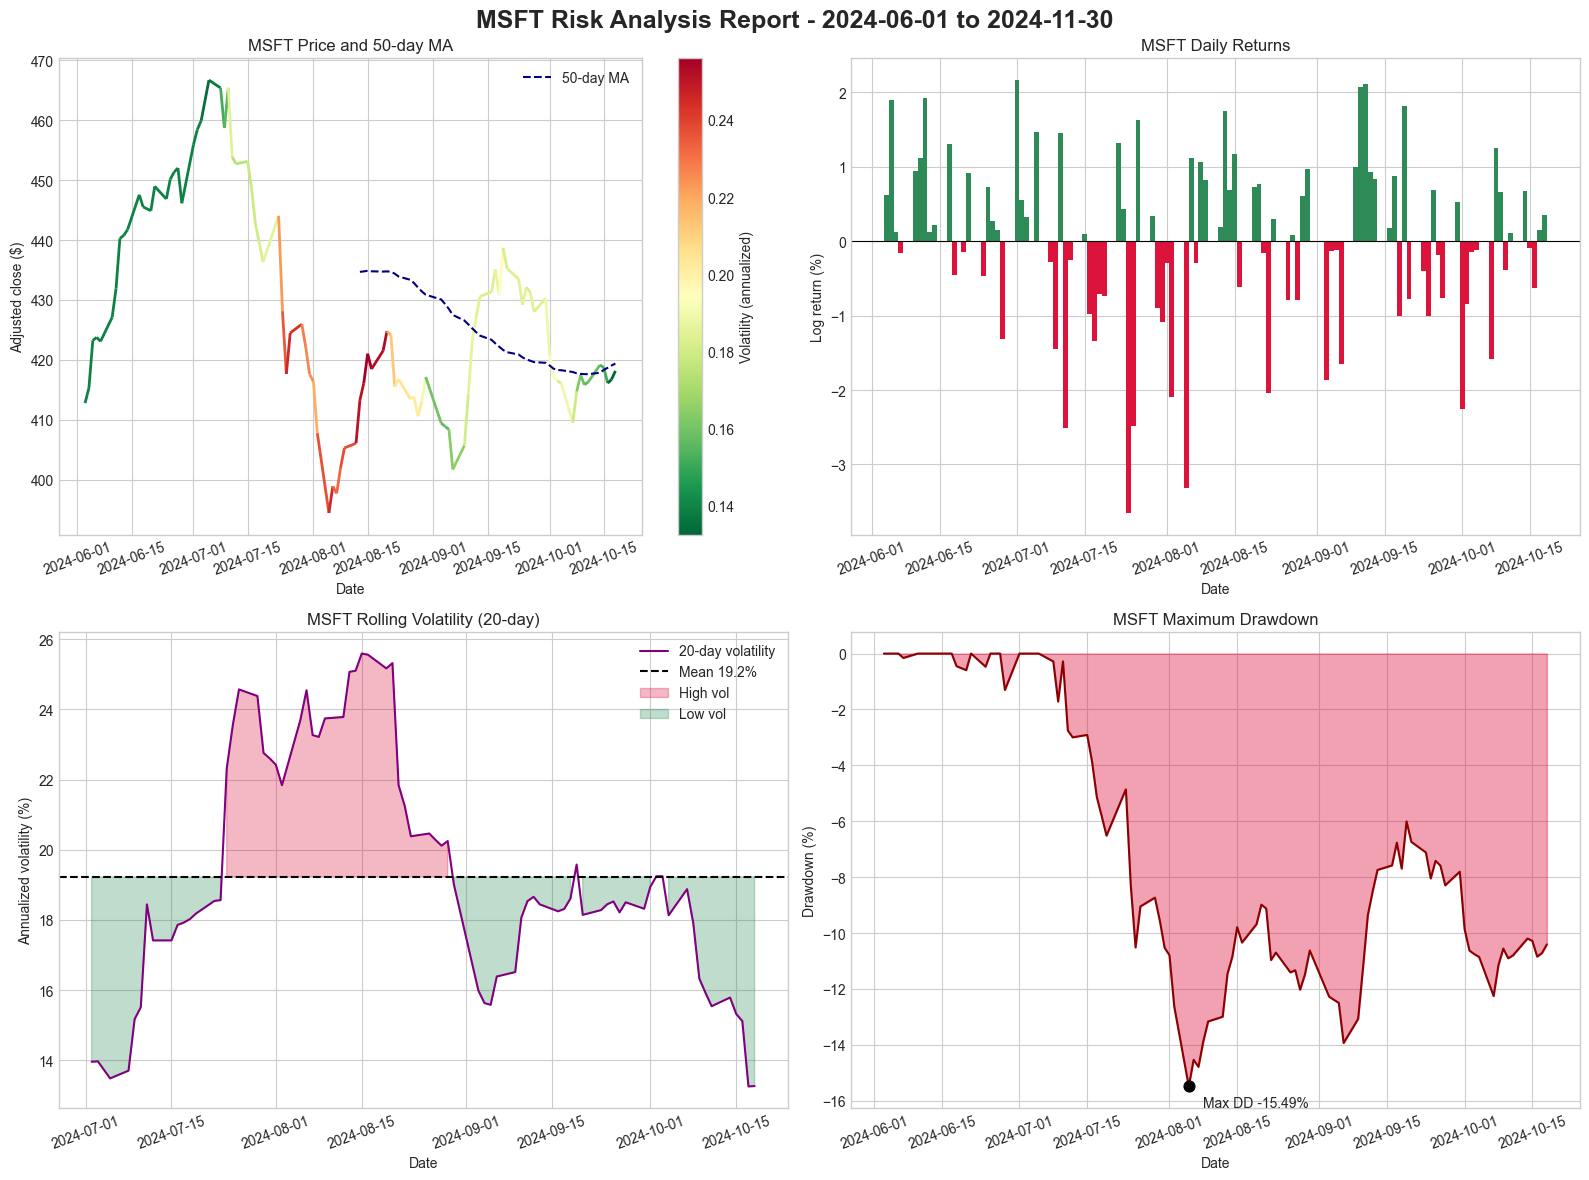

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')
dates = df.index.to_numpy()

ax = axes[0, 0]
x = plt.matplotlib.dates.date2num(dates)
points = np.column_stack([x, df['adj_close']]).reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
vol = df['volatility'].bfill().to_numpy()
line = LineCollection(segments, cmap='RdYlGn_r', norm=plt.Normalize(np.nanmin(vol), np.nanmax(vol)), linewidth=2)
line.set_array(vol[1:])
ax.add_collection(line)
ax.autoscale()
ax.xaxis_date()
ax.plot(df.index, df['ma_50'], color='navy', linestyle='--', label='50-day MA')
fig.colorbar(line, ax=ax, label='Volatility (annualized)')
ax.set(title=f'{ticker} Price and 50-day MA', xlabel='Date', ylabel='Adjusted close ($)')
ax.legend()

ax = axes[0, 1]
colors = np.where(df['return'] >= 0, 'seagreen', 'crimson')
ax.bar(df.index, df['return'] * 100, color=colors, width=1)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title=f'{ticker} Daily Returns', xlabel='Date', ylabel='Log return (%)')

ax = axes[1, 0]
mean_vol = df['volatility'].mean()
ax.plot(df.index, df['volatility'] * 100, color='purple', label='20-day volatility')
ax.axhline(mean_vol * 100, color='black', linestyle='--', label=f'Mean {mean_vol:.1%}')
ax.fill_between(df.index, df['volatility'] * 100, mean_vol * 100, where=df['volatility'] > mean_vol, color='crimson', alpha=0.3, label='High vol')
ax.fill_between(df.index, df['volatility'] * 100, mean_vol * 100, where=df['volatility'] < mean_vol, color='seagreen', alpha=0.3, label='Low vol')
ax.set(title=f'{ticker} Rolling Volatility (20-day)', xlabel='Date', ylabel='Annualized volatility (%)')
ax.legend()

ax = axes[1, 1]
worst = df['drawdown'].idxmin()
ax.fill_between(df.index, df['drawdown'] * 100, 0, color='crimson', alpha=0.4)
ax.plot(df.index, df['drawdown'] * 100, color='darkred')
ax.scatter(worst, df.loc[worst, 'drawdown'] * 100, color='black', zorder=3, s=60)
ax.annotate(f'Max DD {df["drawdown"].min():.2%}', (worst, df.loc[worst, 'drawdown'] * 100), xytext=(10, -15), textcoords='offset points')
ax.set(title=f'{ticker} Maximum Drawdown', xlabel='Date', ylabel='Drawdown (%)')

for ax in axes.flat:
    ax.grid(True)
    ax.tick_params(axis='x', labelrotation=20)
fig.tight_layout()
plt.show()

## Summary statistics

In [7]:
r = df['return'].dropna()
total_return = df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1
summary = pd.DataFrame({'Value': [
    f'{total_return:+.2%}',
    f'{(1 + total_return) ** (252 / len(r)) - 1:+.2%}',
    f'{r.std() * np.sqrt(252):.2%}',
    f'{sharpe:.2f}',
    f'{df["drawdown"].min():.2%}',
    f'{r.max():+.2%}',
    f'{r.min():+.2%}',
    f'{(r > 0).mean():.1%}',
    f'{r[r > 0].mean():+.2%}',
    f'{r[r < 0].mean():+.2%}',
]}, index=['Total Return', 'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio', 'Maximum Drawdown',
           'Best Day', 'Worst Day', 'Positive Days', 'Average Up Day', 'Average Down Day'])
summary.index.name = 'Metric'
display(summary)

,Value
Metric,
Total Return,+1.30%
Annualized Return,+3.46%
Annualized Volatility,18.74%
Sharpe Ratio,0.07
Maximum Drawdown,-15.49%
Best Day,+2.16%
Worst Day,-3.65%
Positive Days,54.2%
Average Up Day,+0.86%


In [8]:
sb.glue('ticker', ticker)
sb.glue('avg_daily_return', float(r.mean()))
sb.glue('avg_volatility', float(df['volatility'].mean()))
sb.glue('max_drawdown', float(df['drawdown'].min()))
sb.glue('sharpe_ratio', float(sharpe))
sb.glue('total_return', float(total_return))